In [59]:
from bs4 import BeautifulSoup
import requests

import lxml
import html5lib
from urllib.parse import urljoin

import time
import os

%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [60]:
# ! pip install html51

In [61]:
# Exchange rates

# inflation

# monetaty policy

url = "https://www.cbsl.gov.lk"

In [62]:
url = "https://www.cbsl.gov.lk"
url

response2 = requests.get(url)
href = "/en/measures-of-consumer-price-inflation"
new_url = urljoin(url,href)
new_url

'https://www.cbsl.gov.lk/en/measures-of-consumer-price-inflation'

In [63]:
response3 = requests.get(new_url)
response3.text

'<!DOCTYPE html PUBLIC "-//W3C//DTD XHTML 1.0 Transitional//EN" "http://www.w3.org/TR/xhtml1/DTD/xhtml1-transitional.dtd">\n<html xmlns="http://www.w3.org/1999/xhtml" xml:lang="en" lang="en" dir="ltr">\n  <head>\n    <meta http-equiv="Content-Type" content="text/html; charset=utf-8" />\n<link rel="shortcut icon" href="https://www.cbsl.gov.lk/sites/default/files/logo_0_0.jpg" type="image/jpeg" />\n<meta name="description" content="Consumer Price Inflation" />\n<meta name="generator" content="Drupal 7 (http://drupal.org)" />\n<link rel="canonical" href="https://www.cbsl.gov.lk/en/measures-of-consumer-price-inflation" />\n<link rel="shortlink" href="https://www.cbsl.gov.lk/en/node/81" />\n    <title>Measures of Consumer Price Inflation | Central Bank of Sri Lanka</title>\n    <!-- META FOR IOS & HANDHELD -->\n    <meta name="viewport" content="width=device-width, initial-scale=1.0, maximum-scale=1.0, user-scalable=yes"/>\n    <meta name="HandheldFriendly" content="true" />\n    <meta name

In [64]:
soup = BeautifulSoup(response3.text,"html.parser")
iframes = soup.find_all("iframe")
iframes

[<iframe frameborder="0" height="205" src="https://www.youtube.com/embed/yaiy80XciBk" width="249"></iframe>,
 <iframe frameborder="0" height="203" src="https://www.youtube.com/embed/fd528EYXR4w" width="246"></iframe>,
 <iframe frameborder="0" height="100%" src="/cbsl_custom/param/inflationchart.php" width="100%">
 </iframe>,
 <iframe frameborder="0" height="100%" src="/cbsl_custom/inflation/inflationwindow.php" width="100%">
 </iframe>]

In [65]:
for i,iframe in enumerate(iframes):
    src = iframe.get("src")
    if src:
        iframe_url = urljoin(url,src)
        print(i+1,iframe_url)
        
        try:
            tables = pd.read_html(iframe_url)
            
            print("Tables found:", len(tables))
 
            for j, table in enumerate(tables):
                print("Table:", j)
                display(table)
 
        except ValueError:
            print("No table found")
            


1 https://www.youtube.com/embed/yaiy80XciBk
No table found
2 https://www.youtube.com/embed/fd528EYXR4w
No table found
3 https://www.cbsl.gov.lk/cbsl_custom/param/inflationchart.php
No table found
4 https://www.cbsl.gov.lk/cbsl_custom/inflation/inflationwindow.php
Tables found: 2
Table: 0


,0,1,2,3,4
0,Date,"Colombo Consumer Price Index (CCPI) (CCPI, 202...","Colombo Consumer Price Index (CCPI) (CCPI, 202...","National Consumer Price Index (NCPI) (NCPI, 2...","National Consumer Price Index (NCPI) (NCPI, 2..."
1,NaN,Headline Inflation (Y-o-Y),Core Inflation (Y-o-Y),Headline Inflation (Y-o-Y),Core Inflation (Y-o-Y)
2,2026,2026,2026,2026,2026
3,January,2.30,2.30,2.40,2.20
4,February,1.60,2.10,1.60,2.20
5,March,2.20,2.50,2.40,2.70
6,April,5.40,3.80,4.70,4.40
7,May,5.50,3.90,5.40,4.50
8,June,6.80,4.00,6.50,5.00
9,July,7.30,4.40,-,-


Table: 1


,0,1,2,3,4
0,Date,"Colombo Consumer Price Index (CCPI) (CCPI, 201...","Colombo Consumer Price Index (CCPI) (CCPI, 201...","National Consumer Price Index (NCPI) (NCPI, 2...","National Consumer Price Index (NCPI) (NCPI, 2..."
1,NaN,Headline Inflation (Y-o-Y),Core Inflation (Y-o-Y),Headline Inflation (Y-o-Y),Core Inflation (Y-o-Y)
2,2022,2022,2022,2022,2022
3,January,14.20,9.90,16.80,12.90
4,February,15.10,10.90,17.50,14.10
5,March,18.70,13.00,21.50,17.30
6,April,29.80,22.00,33.80,27.90
7,May,39.10,28.40,45.30,37.70
8,June,54.60,39.90,58.90,49.30
9,July,60.80,44.30,66.70,57.30


2022

Colombo Consumer Price Index (CCPI)

National Consumer Price Index (NCPI)

In [66]:
df = pd.DataFrame(table)
df_2022 = df.loc[0:14]

df_2022 = df_2022.rename(columns={
    df_2022.columns[0]: 'Date-2022',
    df_2022.columns[1]: 'CCPI Headline Inflation',
    df_2022.columns[2]: 'CCPI Core Inflation',
    df_2022.columns[3]: 'NCPI Headline Inflation',
    df_2022.columns[4]: 'NCPI Core Inflation'

})
df_2022 = df_2022.drop([0,1,2])
# df_2022.iloc[0, 1:] = ''
df_2022

,Date-2022,CCPI Headline Inflation,CCPI Core Inflation,NCPI Headline Inflation,NCPI Core Inflation
3,January,14.20,9.90,16.80,12.90
4,February,15.10,10.90,17.50,14.10
5,March,18.70,13.00,21.50,17.30
6,April,29.80,22.00,33.80,27.90
7,May,39.10,28.40,45.30,37.70
8,June,54.60,39.90,58.90,49.30
9,July,60.80,44.30,66.70,57.30
10,August,64.30,46.60,70.20,60.50
11,September,69.80,50.20,73.70,64.10
12,October,66.00,49.70,70.60,62.40


In [67]:
df_2022.columns = ['Month', 'CCPI Headline Inflation', 'CCPI Core Inflation', 'NCPI Headline Inflation', 'NCPI Core Inflation']

columns = ['CCPI Headline Inflation', 'CCPI Core Inflation', 'NCPI Headline Inflation', 'NCPI Core Inflation']

df_2022[columns] = df_2022[columns].apply(pd.to_numeric) #(errors='coerce')

In [68]:
df_2022.dtypes

Month                          str
CCPI Headline Inflation    float64
CCPI Core Inflation        float64
NCPI Headline Inflation    float64
NCPI Core Inflation        float64
dtype: object

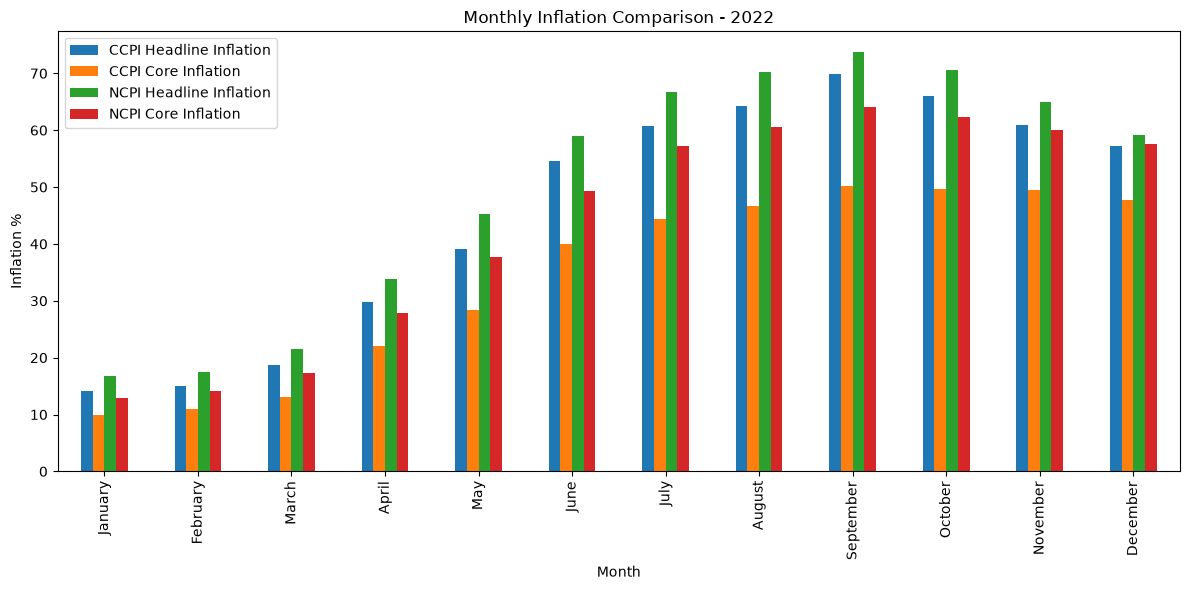

In [69]:
df_2022.columns = [
    'Month',
    'CCPI Headline Inflation',
    'CCPI Core Inflation',
    'NCPI Headline Inflation',
    'NCPI Core Inflation'
]

columns = [
    'CCPI Headline Inflation',
    'CCPI Core Inflation',
    'NCPI Headline Inflation',
    'NCPI Core Inflation'
]

df_2022[columns] = df_2022[columns].apply(
    pd.to_numeric,
    # errors='coerce'
)

df_2022.plot(
    x='Month',
    y=[
        'CCPI Headline Inflation',
        'CCPI Core Inflation',
        'NCPI Headline Inflation',
        'NCPI Core Inflation'
    ],
    kind='bar',
    figsize=(12, 6)
)

plt.title('Monthly Inflation Comparison - 2022')
plt.xlabel('Month')
plt.ylabel('Inflation %')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

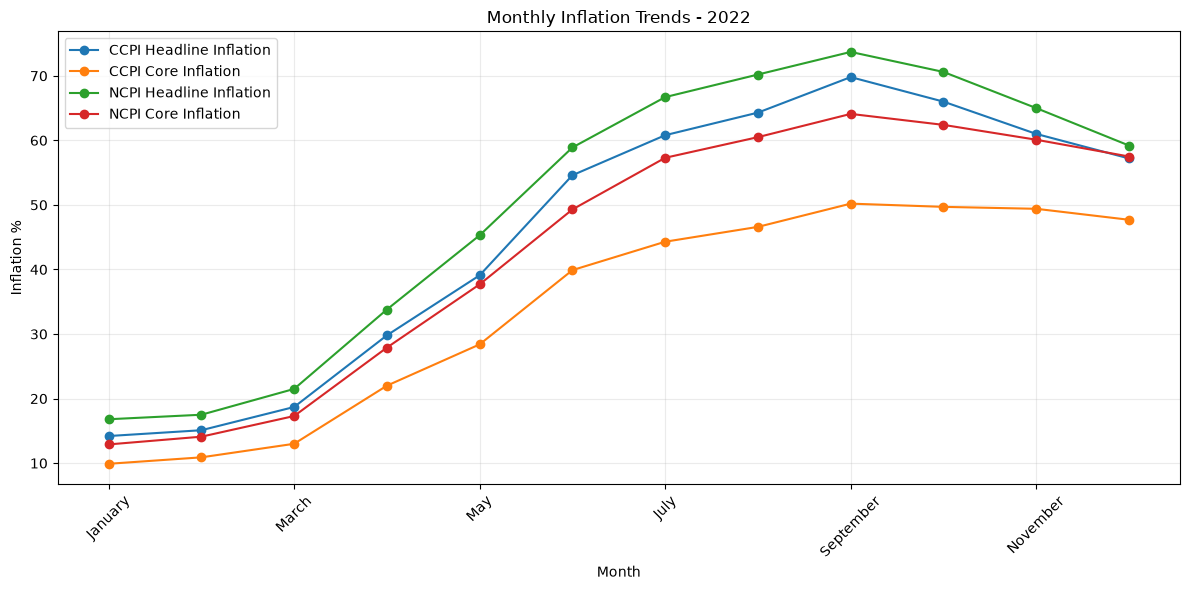

In [70]:
df_2022.plot(
    x='Month',
    y=columns,
    kind='line',
    marker='o',
    figsize=(12, 6)
)

plt.title('Monthly Inflation Trends - 2022')
plt.xlabel('Month')
plt.ylabel('Inflation %')
plt.xticks(rotation=45)
plt.grid(True,alpha=0.25)
plt.tight_layout()
plt.show()

In [1]:
# folder_name = "Inflation"
# os.makedirs(folder_name,exist_ok=True)
# df_2022.to_csv(f"{folder_name}/2022-inflation.csv",index=False)

2021

In [ ]:
# df_2021 = df.loc[15:27]

# df_2021 = df_2021.rename(columns={
#     df_2021.columns[0]: 'Date',


# })

# df_2021

In [78]:
# import requests

# import pandas as pd

# from bs4 import BeautifulSoup

# from urllib.parse import urljoin
 
# # ============================================================

# # CBSL PAGE

# # ============================================================
 
# url = "https://www.cbsl.gov.lk/en/measures-of-consumer-price-inflation"
 
# response = requests.get(url)

# soup = BeautifulSoup(response.text, "html.parser")
 
# iframes = soup.find_all("iframe")
 
# print("Number of iframes:", len(iframes))
 
 
# # ============================================================

# # FIND CBSL INFLATION IFRAME

# # ============================================================
 
# for i, iframe in enumerate(iframes):
 
#     src = iframe.get("src")
 
#     if not src:

#         continue
 
#     iframe_url = urljoin(url, src)
 
#     print("\nIframe:", i)

#     print(iframe_url)
 
#     try:
 
#         tables = pd.read_html(iframe_url)
 
#         print("Tables found:", len(tables))
 
#         if len(tables) < 2:

#             continue
 
 
#         # ====================================================

#         # TABLE 0

#         # 2024, 2025, 2026

#         # ====================================================
 
#         table_0 = tables[0].copy()
 
#         print("\n====================================")

#         print("TABLE 0")

#         print("====================================")
 
#         display(table_0)
 
 
#         # Find year rows in Table 0

#         year_rows_0 = []
 
#         for index in range(len(table_0)):
 
#             row = table_0.iloc[index]
 
#             # Check all cells in the row

#             for value in row:
 
#                 value = str(value).strip()
 
#                 if value.isdigit():
 
#                     year = int(value)
 
#                     if 2000 <= year <= 2100:
 
#                         year_rows_0.append(

#                             (index, year)

#                         )
 
#                         break
 
 
#         print("\nYears found in Table 0:")

#         print(year_rows_0)
 
 
#         # Remove duplicate year rows

#         year_rows_0 = list(

#             dict.fromkeys(year_rows_0)

#         )
 
 
#         # Dictionary for Table 0

#         table0_yearly = {}
 
 
#         # ====================================================

#         # SPLIT TABLE 0 BY YEAR

#         # ====================================================
 
#         for n, (start_row, year) in enumerate(year_rows_0):
 
#             if n + 1 < len(year_rows_0):
 
#                 end_row = year_rows_0[n + 1][0]
 
#             else:
 
#                 end_row = len(table_0)
 
 
#             year_data = table_0.iloc[

#                 start_row + 1:end_row

#             ].copy()
 
 
#             # Add year

#             year_data.insert(

#                 0,

#                 "Year",

#                 year

#             )
 
 
#             table0_yearly[year] = year_data.reset_index(

#                 drop=True

#             )
 
 
#         # ====================================================

#         # DISPLAY TABLE 0 YEAR BY YEAR

#         # ====================================================
 
#         print("\n\nTABLE 0 - YEARS")
 
#         for year in sorted(table0_yearly.keys()):
 
#             print("\n------------------------------------")

#             print(f"YEAR {year}")

#             print("------------------------------------")
 
#             display(

#                 table0_yearly[year]

#             )
 
 
#         # ====================================================

#         # TABLE 1

#         # 2020, 2021, 2022, etc.

#         # ====================================================
 
#         table_1 = tables[1].copy()
 
#         print("\n====================================")

#         print("TABLE 1")

#         print("====================================")
 
#         display(table_1.head(15))
 
 
#         # ====================================================

#         # FIND YEAR ROWS IN TABLE 1

#         # ====================================================
 
#         year_rows_1 = []
 
#         for index in range(len(table_1)):
 
#             value = str(

#                 table_1.iloc[index, 0]

#             ).strip()
 
#             if value.isdigit():
 
#                 year = int(value)
 
#                 if 2000 <= year <= 2100:
 
#                     year_rows_1.append(

#                         (index, year)

#                     )
 
 
#         print("\nYears found in Table 1:")

#         print(year_rows_1)
 
 
#         # ====================================================

#         # SPLIT TABLE 1 BY YEAR

#         # ====================================================
 
#         table1_yearly = {}
 
 
#         for n, (start_row, year) in enumerate(year_rows_1):
 
#             if n + 1 < len(year_rows_1):
 
#                 end_row = year_rows_1[n + 1][0]
 
#             else:
 
#                 end_row = len(table_1)
 
 
#             year_data = table_1.iloc[

#                 start_row + 1:end_row

#             ].copy()
 
 
#             year_data.insert(

#                 0,

#                 "Year",

#                 year

#             )
 
 
#             table1_yearly[year] = year_data.reset_index(

#                 drop=True

#             )
 
 
#         # ====================================================

#         # DISPLAY TABLE 1 YEAR BY YEAR

#         # ====================================================
 
#         print("\n\nTABLE 1 - YEARS")
 
#         for year in sorted(table1_yearly.keys()):
 
#             print("\n------------------------------------")

#             print(f"YEAR {year}")

#             print("------------------------------------")
 
#             display(

#                 table1_yearly[year]

#             )
 
 
#         # ====================================================

#         # COMBINE ALL YEARS

#         # ====================================================
 
#         all_years = {}
 
#         all_years.update(table1_yearly)

#         all_years.update(table0_yearly)
 
 
#         print("\n\n====================================")

#         print("ALL YEARS AVAILABLE")

#         print("====================================")
 
#         print(

#             sorted(all_years.keys())

#         )
 
 
#     except Exception as e:
 
#         print("Error:", e)
 